# Wine Quality Prediction

Predict red-wine `quality` (0–10 sensory score) from 11 physicochemical measurements.
Dataset: `winequality.csv` (UCI Wine Quality, red wine subset, 1,599 samples).

# Importing the required libraries :

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# Importing the dataset :

In [2]:
df = pd.read_csv("winequality.csv")
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [3]:
df.shape

(1599, 12)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


# Data Preprocessing :

In [5]:
# CHECKING FOR NULL VALUES
df.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

In [6]:
# DUPLICATE ROWS
print('Duplicate rows:', df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print('Shape after dropping duplicates:', df.shape)

Duplicate rows: 240
Shape after dropping duplicates: (1359, 12)


In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1359.0,8.310596,1.736990,4.60000,7.1000,7.9000,9.20000,15.90000
volatile acidity,1359.0,0.529478,0.183031,0.12000,0.3900,0.5200,0.64000,1.58000
citric acid,1359.0,0.272333,0.195537,0.00000,0.0900,0.2600,0.43000,1.00000
residual sugar,1359.0,2.523400,1.352314,0.90000,1.9000,2.2000,2.60000,15.50000
chlorides,1359.0,0.088124,0.049377,0.01200,0.0700,0.0790,0.09100,0.61100
free sulfur dioxide,1359.0,15.893304,10.447270,1.00000,7.0000,14.0000,21.00000,72.00000
total sulfur dioxide,1359.0,46.825975,33.408946,6.00000,22.0000,38.0000,63.00000,289.00000
density,1359.0,0.996709,0.001869,0.99007,0.9956,0.9967,0.99782,1.00369
pH,1359.0,3.309787,0.155036,2.74000,3.2100,3.3100,3.40000,4.01000
sulphates,1359.0,0.658705,0.170667,0.33000,0.5500,0.6200,0.73000,2.00000


# Exploratory Analysis :

quality
3     10
4     53
5    577
6    535
7    167
8     17
Name: count, dtype: int64


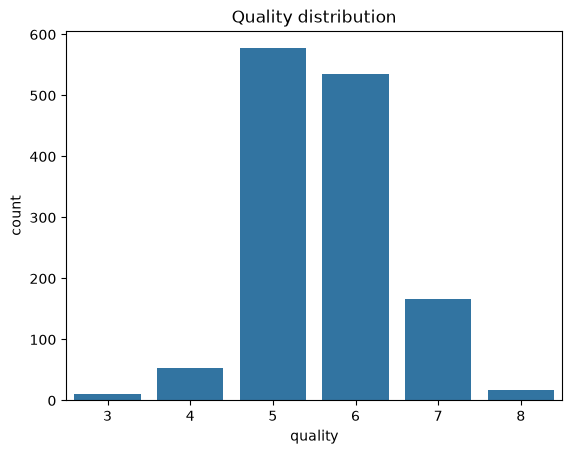

In [8]:
# DISTRIBUTION OF THE TARGET
print(df['quality'].value_counts().sort_index())
sns.countplot(x='quality', data=df)
plt.title('Quality distribution')
plt.show()

In [9]:
# CORRELATION OF EACH FEATURE WITH QUALITY
df.corr()['quality'].drop('quality').sort_values(ascending=False)

alcohol                 0.480343
sulphates               0.248835
citric acid             0.228057
fixed acidity           0.119024
residual sugar          0.013640
free sulfur dioxide    -0.050463
pH                     -0.055245
chlorides              -0.130988
total sulfur dioxide   -0.177855
density                -0.184252
volatile acidity       -0.395214
Name: quality, dtype: float64

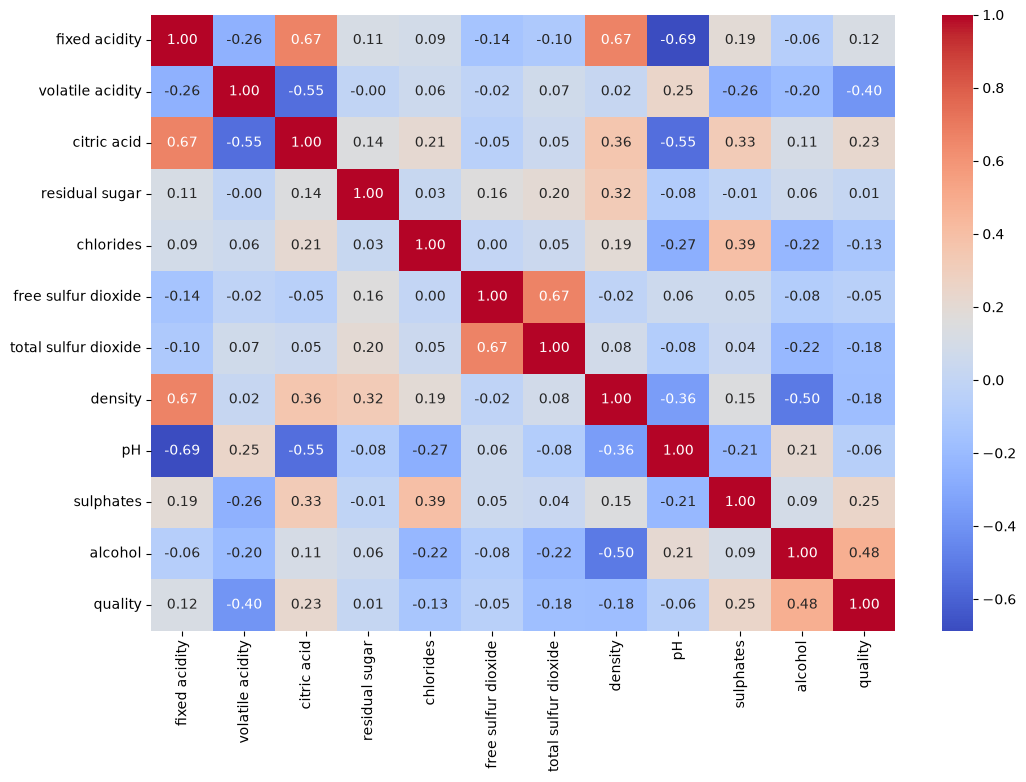

In [10]:
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(), cmap='coolwarm', annot=True, fmt='.2f')
plt.show()

# Spliting The Dataset :

In [11]:
from sklearn.model_selection import train_test_split
X = df.drop('quality', axis=1)
y = df['quality']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
len(X_train), len(X_test)

(951, 408)

# Linear Regression :

In [12]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

print('R2  :', round(r2_score(y_test, y_pred_lr), 4))
print('MAE :', round(mean_absolute_error(y_test, y_pred_lr), 4))
print('RMSE:', round(np.sqrt(mean_squared_error(y_test, y_pred_lr)), 4))

R2  : 0.3815
MAE : 0.4944
RMSE: 0.647


In [13]:
# COEFFICIENTS
pd.Series(lr.coef_, index=X.columns).sort_values()

chlorides               -1.961599
volatile acidity        -0.995252
pH                      -0.824192
fixed acidity           -0.031589
residual sugar          -0.019768
total sulfur dioxide    -0.003717
free sulfur dioxide      0.006649
citric acid              0.019772
alcohol                  0.302573
sulphates                0.896605
density                 21.142891
dtype: float64

# Random Forest Regressor (comparison) :

In [14]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

print('R2  :', round(r2_score(y_test, y_pred_rf), 4))
print('MAE :', round(mean_absolute_error(y_test, y_pred_rf), 4))
print('RMSE:', round(np.sqrt(mean_squared_error(y_test, y_pred_rf)), 4))

R2  : 0.4373
MAE : 0.4732
RMSE: 0.6171


In [15]:
pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

alcohol                 0.269003
sulphates               0.131634
volatile acidity        0.124101
total sulfur dioxide    0.081468
chlorides               0.065681
residual sugar          0.062329
pH                      0.061946
density                 0.056323
fixed acidity           0.051959
free sulfur dioxide     0.048132
citric acid             0.047424
dtype: float64

# Evaluation :

Rounding the regression output to the nearest integer gives the share of test wines whose quality score is predicted exactly.

In [16]:
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'R2': [r2_score(y_test, y_pred_lr), r2_score(y_test, y_pred_rf)],
    'MAE': [mean_absolute_error(y_test, y_pred_lr), mean_absolute_error(y_test, y_pred_rf)],
    'Exact-score accuracy (rounded)': [(np.rint(y_pred_lr) == y_test).mean(), (np.rint(y_pred_rf) == y_test).mean()],
}).round(4)
results

,Model,R2,MAE,Exact-score accuracy (rounded)
0,Linear Regression,0.3815,0.4944,0.6054
1,Random Forest,0.4373,0.4732,0.6569
